[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eirasf/GCED-AA2/blob/main/es/lab8/lab8.ipynb)

# Práctica 8: Transfer learning

## Pre-requisitos

### Instalar paquetes

In [1]:
!pip install pytorch-lightning

In [2]:
# --- Imports generales y de entorno ---
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import pytorch_lightning as pl

# Transfer learning sobre Stanford Dogs

Lo que queremos hacer es entrenar un clasificador para que catalogue las distintas clases de perros almacenadas en el dataset Stanford Dogs. Para ello, lo primero que tenemos que hacer es descargar y descomprimir el dataset.

In [3]:
import urllib.request

print('Downloading...')
urllib.request.urlretrieve("https://www.kaggle.com/api/v1/datasets/download/jessicali9530/stanford-dogs-dataset", "stanford-dogs.zip")
print("Download complete! Unzipping...")

import zipfile
with zipfile.ZipFile("stanford-dogs.zip", "r") as zip_ref:
    zip_ref.extractall("stanford_dogs")
print("Your data is ready!")


Downloading...
Download complete! Unzipping...
Your data is ready!


El dataset ya está descargado en tu carpeta local (en Colab, puedes verlo en el icono de la carpeta que aparece a la izquierda).

### Paso a tensores de torch

Ahora cargaremos las imágenes en un dataset de tensores de torch. Necesitamos indicarle cómo adaptar cada imagen para procesarla con nuestra red. Para ello utilizaremos `torchvision.transforms` para crear una transformación que sea una composición de estas transformaciones sencillas:
1. Escalar todas las imágenes a un mismo tamaño ([Resize](https://docs.pytorch.org/vision/main/generated/torchvision.transforms.Resize.html))
1. Quedarnos solo con un cuadro central de 224x224 ([CenterCrop](https://docs.pytorch.org/vision/main/generated/torchvision.transforms.CenterCrop.html))
1. Pasar a tensor ([ToTensor](https://docs.pytorch.org/vision/main/generated/torchvision.transforms.ToTensor.html))
1. Adaptar la escala de los valores para facilitar el entreno estandarizando los valores de los píxeles para que su distribución se asemeje a una N(0,1) ([Normalize](https://docs.pytorch.org/vision/main/generated/torchvision.transforms.Normalize.html)). Esto lo hacemos restando a cada pixel el valor medio de los píxeles en el conjunto Imagenet y dividiendo el resultado por la desviación típica de estos mismos píxeles.

In [4]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

transform = transforms.Compose([
    # Redimensionamos las imágenes al tamaño estándar que esperan los modelos preentrenados (224x224)
    transforms.Resize((224, 224)),
    # Convertimos la imagen de PIL/NumPy a un tensor de PyTorch (con valores entre 0 y 1)
    transforms.ToTensor(),
    # Normalizamos utilizando las medias y desviaciones estándar oficiales de ImageNet
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Load using ImageFolder
train_dir = "stanford_dogs/images/Images"

# Cargamos el dataset completo pasando la ruta y el transformador definido
full_dataset = datasets.ImageFolder(root=train_dir, transform=transform)

print(f"Dataset cargado con éxito. Clases totales: {len(full_dataset.classes)}")

Dataset cargado con éxito. Clases totales: 120


### Particiones de entrenamiento y test
Dejaremos el 20% de los datos para test. Utilizaremos `torch.utils.data.random_split` sobre `full_dataset` para conseguir dos datasets separados.

In [5]:
import torch
from torch.utils.data import random_split

# Calculamos el tamaño de cada partición (80% train, 20% test)
test_size = int(0.2 * len(full_dataset))
train_size = len(full_dataset) - test_size

# Opcional: Definimos una semilla para que la división sea reproducible
generator = torch.Generator().manual_seed(1234)

# Dividimos el dataset
train_dataset, test_dataset = random_split(
    full_dataset, [train_size, test_size], generator=generator
)

print(f"Muestras de entrenamiento: {len(train_dataset)}")
print(f"Muestras de test: {len(test_dataset)}")

Muestras de entrenamiento: 16464
Muestras de test: 4116


## Visualización

Echemos un vistazo a unas cuantas imágenes.

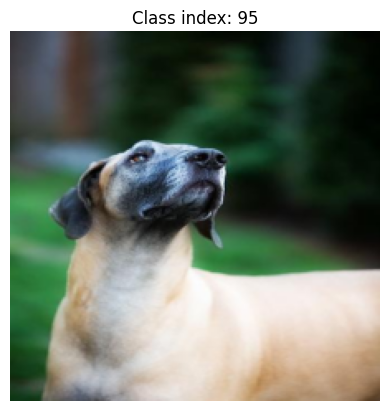

Image tensor shape: torch.Size([3, 224, 224])


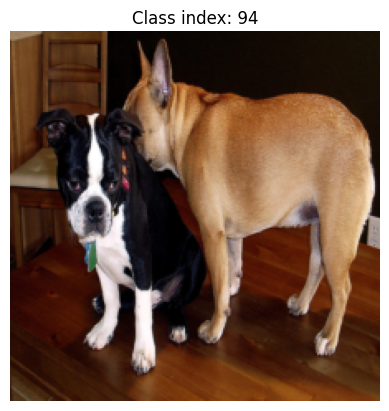

Image tensor shape: torch.Size([3, 224, 224])


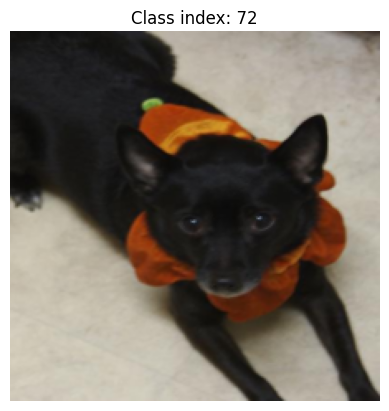

Image tensor shape: torch.Size([3, 224, 224])


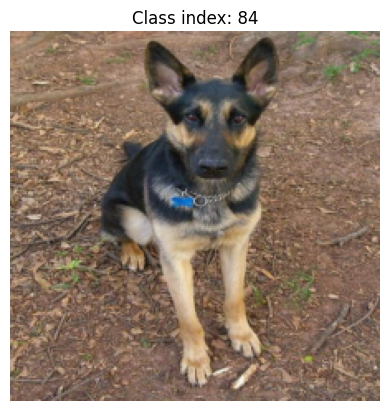

Image tensor shape: torch.Size([3, 224, 224])


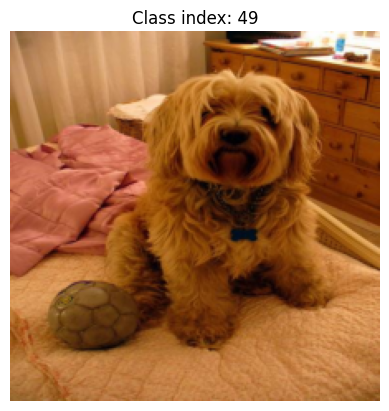

Image tensor shape: torch.Size([3, 224, 224])


In [6]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

# TODO - Crea un DataLoader a partir del test_subset
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

def show_image(image_tensor, label_tensor):
  # Unnormalize
  mean = torch.tensor(IMAGENET_MEAN)
  std = torch.tensor(IMAGENET_STD)
  img = image_tensor.permute(1, 2, 0) * std + mean  # CHW → HWC and undo normalization
  img = img.clamp(0, 1)  # keep in [0,1] for matplotlib

  # Show image and print details
  plt.imshow(img.numpy())
  plt.title(f"Class index: {label_tensor.item()}")
  plt.axis("off")
  plt.show()

  print(f"Image tensor shape: {images[0].shape}")

# Get one batch from the train_loader
images, labels = next(iter(test_loader))

for i in range(5):
  # Pick one example
  img = images[i]
  label = labels[i]

  show_image(img, label)

## Creando el modelo

Una vez sabemos preparar debidamente los datos, vamos a crear el modelo. Nuestro modelo constará de tres partes diferenciadas:

1. Data augmentation
1. DenseNet121 preentrenado
1. Clasificador

Vamos a ir paso a paso creando cada uno de los puntos.

### Data augmentation

El primer paso que vamos a realizar es aumentar los datos de entrenamiento mediante la aplicación de distintas transformaciones sobre las imágenes originales. En concreto, vamos a realizar las siguientes operaciones:

1. Rotaciones aleatorias de $2*\pi*0.15$ grados ([RandomRotation](https://docs.pytorch.org/vision/main/generated/torchvision.transforms.RandomRotation.html))
1. Traslaciones aleatorias del $10\%$ del tamaño de la imagen ([RandomAffine](https://docs.pytorch.org/vision/main/generated/torchvision.transforms.RandomAffine.html))
1. Giros aleatorios de la imagen ([RandomHorizontalFlip](https://docs.pytorch.org/vision/main/generated/torchvision.transforms.RandomHorizontalFlip.html))
1. Cambios aleatorios del contraste del $10\%$ ([ColorJitter](https://docs.pytorch.org/vision/main/generated/torchvision.transforms.Compose.html))

La transformación de *data augmentation* será una nueva transformación [Compose](https://docs.pytorch.org/vision/main/generated/torchvision.transforms.Compose.html) que haga esas operaciones. Cambia la `transform` de `train_subset` por una nueva `Compose` que haga la *data augmentation* seguida de la transformación original.

In [7]:
import math
from torchvision import transforms
from torch.utils.data import DataLoader

# 1. Definición de las operaciones de Data Augmentation
rot_degrees = 2 * math.pi * 0.15 * (180 / math.pi)

img_augmentation = transforms.Compose([
    transforms.RandomRotation(degrees=rot_degrees),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)), # 10% de traslación
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(contrast=0.1) # Cambios de contraste del 10%
])

# 2. Combinación con la transformación original
train_transform_augmented = transforms.Compose([
    img_augmentation,
    transform # transform original definida previamente
])

# Asignamos el nombre train_subset por compatibilidad y aplicamos la transformación
train_subset = train_dataset
train_subset.dataset.transform = train_transform_augmented  # Nota: En los Subsets de PyTorch, la transformación suele aplicarse al dataset base o manejarse a través del wrapper.

# 3. Creación del DataLoader para entrenamiento
BATCH_SIZE = 32
train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)



### Descargar un modelo preentrenado


Lo primero que vamos a hacer es descargar un modelo preentrenado. Por suerte, en TorchVision tenemos una serie de modelos ya preentrenados. Se encuentran en el paquete `torchvision.models` ([Doc](https://docs.pytorch.org/vision/main/models.html)). En concreto, vamos a utilizar la red DenseNet121, cuyo esquema podemos ver en la siguiente imagen:

![](https://drive.google.com/uc?export=view&id=1cINnKtOxOtZGxCiZwSXfhku495KHsSvk)

En esencia, es una variante del bloque residual, en donde la salida de una capa se suma a todas las salidas de las capas siguientes.

Para cargar el modelo haremos lo siguiente:

In [8]:
from torchvision import models
# Cargamos la DenseNet121 preentrenada en ImageNet
densenet = models.densenet121(pretrained=True)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet121_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet121_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



En la [documentación](https://docs.pytorch.org/vision/main/models/generated/torchvision.models.densenet121.html) podemos ver que esta red admite, como entrada, imágenes de tamaño 224x224x3. Aunque podemos utilizar cualquier tamaño de entrada (siempre que sea mayor de 32x32x3), vamos a seguir utilizando ese tamaño.

### Crear el clasificador

Para crear el clasificador, lo que vamos a hacer es crear una última capa que será un clasificador lineal. Sin embargo, podemos observar que la salida de la red DenseNet tiene 4 dimensiones, no 2 que es lo necesario para crear el clasificador. Aquí tenemos dos opciones para realizar la conversión:

1. Usar [Flatten](https://docs.pytorch.org/docs/stable/generated/torch.nn.modules.flatten.Flatten.html#flatten), en la que la dimensión 2 será de tamaño la multiplicación de las dimensiones 2, 3 y 4.
1. Usar GlobalPooling, colapsando las dimensiones 2 y 3, siendo por tanto la dimensión 2 de salida igual a la dimensión 4 de entrada.

Aquí podemos ver una imagen ilustrando la diferencia:

![](https://drive.google.com/uc?export=view&id=1I3a2v7cuEjAUVdlLENtCaIq-etCXriGT)

En nuestro caso, vamos a usar un GlobalPooling, en concreto [AdaptiveAveragePool2D](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.adaptive_avg_pool2d.html). A mayores, añadiremos alguna regularización extra como [Dropout](https://docs.pytorch.org/docs/stable/generated/torch.nn.Dropout.html) o [Batch Normalization](https://docs.pytorch.org/docs/stable/generated/torch.ao.nn.quantized.BatchNorm1d.html).

In [9]:
import torch.nn as nn

# 1. Obtenemos el número de características de entrada de la capa original de DenseNet
in_features = densenet.classifier.in_features
num_classes = len(full_dataset.classes)

# 2. Definimos el nuevo clasificador usando esa variable
classifier = nn.Sequential(
    # Global Average Pooling (colapsa las dimensiones espaciales a 1x1)
    nn.AdaptiveAvgPool2d((1, 1)),

    # Aplanamos el tensor para que pase de 4D a 2D (batch_size, num_features)
    nn.Flatten(),

    # Batch Normalization con las características correctas
    nn.BatchNorm1d(in_features),

    # Dropout con probabilidad de 0.2 para regularización
    nn.Dropout(p=0.2),

    # Capa Lineal final (Dense) hacia el número de clases
    nn.Linear(in_features, num_classes),

    # Activación Softmax
    nn.Softmax(dim=1)
)

# 3. Asignamos el nuevo clasificador al modelo
densenet.classifier = classifier

print("¡Clasificador integrado correctamente en DenseNet121 sin errores de atributos!")

¡Clasificador integrado correctamente en DenseNet121 sin errores de atributos!


### Combinando todos los elementos

Una vez creados todos los elementos, sólo nos falta combinarlos. Hay que recordar que la red preentrenada no se modifica, por lo que hay que indicarle que los pesos no son entrenables. Después desecharemos la capa de clasificación de la red y

In [10]:
# Congelamos los pesos de la densenet
for param in densenet.parameters():
    param.requires_grad = False  # freeze all backbone layers

# DenseNet121 tiene dos partes diferenciadas: `densenet.features` que calcula 1024 features a partir de cada imagen
# y densenet.clasifier, que (tras pasarles una ReLU) las utiliza para hacer la predicción sobre Imagenet
# Es esta última parte la que desecharemos
# Haremos un nuevo modelo que coja las capas de densenet.features y le concatene la ReLU final
# Este será el "backbone", la parte preentrenada, de nuestro modelo de clasificación
backbone = torch.nn.Sequential(*list(densenet.features.children()))
backbone.add_module('relu', torch.nn.ReLU(inplace=True))

# TODO - Crea tu modelo como un Sequential que concatene el backbone con el clasificador que
# has declarado en la celda anterior
model = torch.nn.Sequential(
    backbone,
    classifier
)
# Verificación
print(model)

Sequential(
  (0): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): _DenseBlock(
      (denselayer1): _DenseLayer(
        (norm1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu1): ReLU(inplace=True)
        (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu2): ReLU(inplace=True)
        (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      )
      (denselayer2): _DenseLayer(
        (norm1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu1): ReLU(inplace=True)
        

## Entrenando el modelo

Por último, sólo nos queda entrenar el modelo durante 10 iteraciones (ten paciencia, puede llevar sobre 10 minutos). En test, deberíamos tener una precisión cercana al $80\%$. Utiliza `nn.CrossEntropyLoss` como función de pérdida y Adam con lr=0.001 como optimizador (**recuerda que solo le debes pasar los parámetros de la parte clasificadora del modelo**).

In [11]:
# TODO - Entrena el modelo
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Definimos la función de pérdida
criterion = nn.CrossEntropyLoss()

# 2. Optimizador (pasando únicamente los parámetros que requieren gradiente, es decir, el clasificador)
# Aseguramos que los parámetros del clasificador requieran gradientes
for param in classifier.parameters():
    param.requires_grad = True
optimizer = optim.Adam(classifier.parameters(), lr=0.001)

# 3. Configuramos el dispositivo (GPU si está disponible, si no CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

num_epochs = 10

print(f"Iniciando el entrenamiento en el dispositivo: {device}")

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_idx, (images, labels) in enumerate(train_loader):
        images, labels = images.to(device), labels.to(device)

        # Limpiamos los gradientes anteriores
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass y optimización
        loss.backward()
        optimizer.step()

        # Estadísticas
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100. * correct / total

    print(f"Época [{epoch+1}/{num_epochs}] | Loss: {epoch_loss:.4f} | Acc (Train): {epoch_acc:.2f}%")



Iniciando el entrenamiento en el dispositivo: cuda
Época [1/10] | Loss: 4.4144 | Acc (Train): 47.83%
Época [2/10] | Loss: 4.1882 | Acc (Train): 65.94%
Época [3/10] | Loss: 4.1382 | Acc (Train): 69.82%
Época [4/10] | Loss: 4.1229 | Acc (Train): 70.45%
Época [5/10] | Loss: 4.1056 | Acc (Train): 72.10%
Época [6/10] | Loss: 4.0944 | Acc (Train): 73.07%
Época [7/10] | Loss: 4.0866 | Acc (Train): 73.43%
Época [8/10] | Loss: 4.0804 | Acc (Train): 74.02%
Época [9/10] | Loss: 4.0758 | Acc (Train): 74.33%
Época [10/10] | Loss: 4.0721 | Acc (Train): 74.31%


## Fine tuning

Al inicio hemos entrenado el modelo sin tocar los pesos de la red DenseNet. Sin embargo, ahora que ya hemos entrenado las capas finales, podemos reentrenar el modelo al completo. Sin embargo, hay que tener en cuenta una serie de consideraciones.

- La tasa de aprendizaje tiene que ser muy baja. Un valor alto podría eliminar la calidad del entrenamiento inicial, haciendo que el sistema se comporte de manera similar a entrenarlo desde 0.
- Las capas de Batch Normalization se mantienen sin entrenar. Esto es debido a que dificultan el entrenamiento en redes ya entrenadas, y sólo estamos buscando un ajuste fino en el sistema.

In [12]:
# --- 1. Descongelar el backbone manteniendo congeladas las capas de Batch Normalization ---
for name, param in model.named_parameters():
    # Comprobamos si la capa pertenece a BatchNorm (en PyTorch suelen llamarse 'norm', 'bn', etc.)
    if "norm" in name.lower() or "bn" in name.lower():
        param.requires_grad = False
    else:
        param.requires_grad = True

# Aseguramos también que el clasificador siga con requires_grad = True
for param in classifier.parameters():
    param.requires_grad = True

# --- 2. Configurar la pérdida y el optimizador con una tasa de aprendizaje baja ---
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-5)

num_epochs = 5
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

print(f"Iniciando el Fine-Tuning en el dispositivo: {device}")

# --- 3. Bucle de entrenamiento para el Fine-Tuning ---
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_idx, (images, labels) in enumerate(train_loader):
        images, labels = images.to(device), labels.to(device)

        # Limpiamos los gradientes
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)´º
        +


        loss = criterion(outputs, labels)

        # Backward pass y optimización
        loss.backward()
        optimizer.step()

        # Estadísticas
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100. * correct / total

    print(f"Época Fine-Tuning [{epoch+1}/{num_epochs}] | Loss: {epoch_loss:.4f} | Acc (Train): {epoch_acc:.2f}%")

print("¡Fine-Tuning completado con éxito! Tu modelo está listo y optimizado.")

Iniciando el Fine-Tuning en el dispositivo: cuda
Época Fine-Tuning [1/5] | Loss: 4.0339 | Acc (Train): 78.16%
Época Fine-Tuning [2/5] | Loss: 4.0200 | Acc (Train): 79.23%
Época Fine-Tuning [3/5] | Loss: 4.0060 | Acc (Train): 80.76%
Época Fine-Tuning [4/5] | Loss: 4.0013 | Acc (Train): 81.07%
Época Fine-Tuning [5/5] | Loss: 3.9925 | Acc (Train): 82.09%
¡Fine-Tuning completado con éxito! Tu modelo está listo y optimizado.


La precisión en entrenamiento ha subido, pero en test ha bajado. ¿Qué puede estar pasando?

# ¡ENHORABUENA! Has completado la práctica de Transfer Learning.

# ¿Deseas saber más?

El transfer learning no se limita sólo a entrenar las últimas capas. Se pueden utilizar sólo unas pocas capas preentrenadas, y entrenar el resto. No hay límite sobre lo que se puede hacer. Tampoco se restringe a clasificación únicamente. Las *deep features* de un modelo de clasificación suelen ser útiles para modelos de regresión, segmentación, etc.